In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Created on Tue Jun  7 12:02:15 2022

@author: sunms498
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
from os import walk
import pickle
from pathlib import Path
from shapely.geometry import Point
import geopandas as gpd
from geopandas import GeoDataFrame

import numpy as np

import matplotlib.pyplot as plt
import xarray as xr
from matplotlib.colors import LogNorm
import numpy as np

"""
# Adding colorbar
cbar = plt.colorbar(label='Values (log scale)')
cbar.ax.tick_params(labelsize=14)

# Adding labels and title
plt.xlabel('X-axis', fontsize=16)
plt.ylabel('Y-axis', fontsize=16)
plt.title('Log-scaled Image', fontsize=18)

# Show the plot
plt.show()
"""
from pathlib import Path
from matplotlib.colors import LogNorm
################################################################################
#"""
#filename = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_TOC/prediction_map_TOC_noconstraint_supervised_men_CS_constraint05.npy"
filename = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_TOC/prediction_map_dist_CS.npy"
prediction_dist_CS = np.load(filename)
prediction_dist_DO = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_TOC/prediction_map_dist_DO.npy")




uncertainty_map_CS = np.var(prediction_dist_CS, axis = 0)
prediction_map_CS = np.mean(prediction_dist_CS, axis = 0)

uncertainty_map_DO = np.var(prediction_dist_DO, axis = 0)
prediction_map_DO = np.mean(prediction_dist_DO, axis = 0)

uncertainty_map_CS = np.rot90(np.rot90(np.fliplr(uncertainty_map_CS)))
prediction_map_CS = np.rot90(np.rot90(np.fliplr(prediction_map_CS)))


uncertainty_map_DO = np.rot90(np.rot90(np.fliplr(uncertainty_map_DO)))
prediction_map_DO = np.rot90(np.rot90(np.fliplr(prediction_map_DO)))


#filename = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_TOC/uncertainty_map_TOC_noconstraint_supervised_men_CS_constraint05.npy"
#uncertainty_map_CS = np.load(filename)
#uncertainty_map_DO = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_TOC/uncertainty_map_TOC_noconstraint_supervised_men_DO.npy")



dataset_mask = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/masks/mask_deepocean.npy")
dataset_mask = np.rot90(np.rot90(np.fliplr(dataset_mask)))

# Create a copy of pm_CS
pm_overlapped = np.copy(prediction_map_DO)

# Mask the values from pm_CS where mask contains NaN values
pm_overlapped[np.isnan(dataset_mask)] = prediction_map_CS[np.isnan(dataset_mask)]

# Create a copy of pm_CS
um_overlapped = np.copy(uncertainty_map_DO)

# Mask the values from pm_CS where mask contains NaN values
um_overlapped[np.isnan(dataset_mask)] = uncertainty_map_CS[np.isnan(dataset_mask)]


#prediction_dist_overlapped = np.copy(prediction_dist_DO)
#pm_overlapped[np.isnan(dataset_mask)] = prediction_map_CS[np.isnan(dataset_mask)]



"""
pm_overlapped = np.load("/home/sunms498/work/toc-neural-nets/SelectFeaturesRun/predictionmap_parametersharing/prediction_map_parametersharing_sedrate_soft_lambda_06.npy")
"""
import matplotlib.pyplot as plt
import matplotlib.colors as colors

#plt.figure(figsize=[25, 15], dpi=200)

# Create a lognorm instance
#lognorm = colors.LogNorm(vmin=0.01, vmax=800)

# Plot the overlapped array with lognorm
#plt.imshow(pm_overlapped, norm = lognorm,  cmap="turbo")
#cbar = plt.colorbar()
##################################################################################

# Add colorbar
#cbar = plt.colorbar()

#plt.show()

ds=2.6

file_porosity = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/porosity/grl53425-sup-0002-supinfo.grd"
#file_porosity = "file_porosity = "/home/sunms498/Data/paper_porosity/GPSM_Restreppo/prediction.nc""
rootgrp_porosity = xr.open_dataset(Path(file_porosity), format = 'NETCDF4')
                                                                   
dataset_porosity = rootgrp_porosity.variables['z']

dataset_numpy_porosity = dataset_porosity.to_numpy()
dataset_numpy_porosity = np.rot90(np.rot90(np.fliplr(dataset_numpy_porosity)))
"""

file_2020 = "/home/sunms498/Data/paper2020/GPSM_Restreppo/prediction.nc"
#file_porosity = "file_porosity = "/home/sunms498/Data/paper_porosity/GPSM_Restreppo/prediction.nc""
rootgrp_2020 = xr.open_dataset(Path(file_2020), format = 'NETCDF4')


file_2021 = "/home/sunms498/Data/paper2021/GPSM_Restreppo/Log10_prediction_5m.nc"
#file_porosity = "file_porosity = "/home/sunms498/Data/paper_porosity/GPSM_Restreppo/prediction.nc""
rootgrp_2021 = xr.open_dataset(Path(file_2021), format = 'NETCDF4')


latitudes = rootgrp_porosity.variables['y'] # in theory all the same
longitudes = rootgrp_porosity.variables['x']

latitudes2020 = rootgrp_2020.variables['lat'] # in theory all the same
longitudes2020 = rootgrp_2020.variables['lon']

latitudes2021 = rootgrp_2021.variables['lat'] # in theory all the same
longitudes2021 = rootgrp_2021.variables['lon']

dataset_porosity = rootgrp_porosity.variables['z']
dataset_2020 = rootgrp_2020.variables['z']
dataset_2021 = rootgrp_2021.variables['z']


# #plt.figure(figsize=([20,10]), dpi=300);plt.imshow(np.rot90(np.rot90(np.fliplr(dataset_numpy))))
dataset_numpy_porosity = dataset_porosity.to_numpy()
dataset_numpy_porosity = np.rot90(np.rot90(np.fliplr(dataset_numpy_porosity)))

dataset_numpy_2020 = dataset_2020.to_numpy()
dataset_numpy_2020 = np.rot90(np.rot90(np.fliplr(dataset_numpy_2020)))

dataset_numpy_2021 = dataset_2021.to_numpy()
dataset_numpy_2021 = np.rot90(np.rot90(np.fliplr(dataset_numpy_2021)))

dataset2020mar = (1-dataset_numpy_porosity/100)*ds*(10**dataset_numpy_2020)##


def find_nearest(value,vector):
    vector = np.float64(vector)-np.float64(value);
    return np.argmin(np.abs(vector))


# data_path = Path(Path().resolve().parents[2] / "Data" / "RestrepoKNNsSed") 
# sed_labels_file = "sediments_all_updated.xlsx"

# df = pd.read_excel(Path(data_path / sed_labels_file))

# df = df[["Latitude","Longitude","Sedimentation rate [cm/ka]"]]
# df = df[df["Longitude"]>-180]
# df = df.dropna(how="any")
# df = df[df["Sedimentation rate [cm/ka]"]<200]

# world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
# geometry = [Point(xy) for xy in zip(df['Longitude'], df['Latitude'])]
# gdf = GeoDataFrame(df, geometry=geometry)  
# fig, ax=plt.subplots(figsize=(20,10), dpi=300)
# gdf.plot(ax = world.plot(ax=ax), column = df["Sedimentation rate [cm/ka]"], vmin = 0, vmax = 200,legend = True, legend_kwds={"label":"{Sedimentation rate [cm/ka]}"});
# fig.tight_layout(pad=0)
# ax.set_xlim(-180,180)
# ax.set_ylim(-90,90)
# fig.savefig("/home/sunms498/work/Img/sedimentation_labels.png", bbox_inches='tight', pad_inches=0)
# df.describe()

"""
#feature_image_path ="../../../Data/LeeKNNsTOC/RestrepoFeatureMaps/"
restrepo_features_path = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/GL_LATITUDE_DD.5m.nc"
#restrepo_features_path_flipped = Path("/media/sunms498/EXTERNAL_USB/Features_Phrampus_flipped")
restrepo_files = []

for (dirpath, dirnames, filenames) in walk(restrepo_features_path):
    restrepo_files.extend(filenames)

restrepo_files.sort()
len(restrepo_files)

rootgrp = xr.open_dataset(restrepo_features_path, format = 'NETCDF4')
latitudes = rootgrp.variables['lat']
longitudes = rootgrp.variables['lon']

# restrepo_features = np.empty([len(df),len(restrepo_files[0:len(restrepo_files)])])
# restrepo_features[:] = np.nan
# restrepo_X_mean = np.empty(0)
# restrepo_X_std = np.empty(0)

file_idx = -1
corrupted_files = 0


 
rootgrp = xr.open_dataset(restrepo_features_path, format = 'NETCDF4')


    
#     latitudes = rootgrp.variables['lats'] # in theory all the same
#     longitudes = rootgrp.variables['lons']

dataset = rootgrp.variables['data']
area = 9.297**2 * np.cos(dataset/180 * np.pi)




land_file = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/island_map.npy")
land_map = np.load(land_file)
land_map[np.isnan(land_map)] = 1


pm_overlapped[land_map] = 0
um_overlapped[land_map] = 0
"""
# prediction_map = np.load("prediction_map(withoutlog)RestrepoFeats__AllVS0.2.npy")
# prediction_map_flipped= np.rot90(np.rot90(np.fliplr(prediction_map)))
# prediction_map_flipped[land_map]=np.nan

# mar_naveen = (1-(dataset_numpy_porosity/100))*ds*(prediction_map_flipped/1e3)

#prediction_map_nonan= np.load("Sed_regresion_083_RestrepoFeats_AllVS0.2_noNaN.npy")
prediction_map_nonan= pm_overlapped#np.load("/home/sunms498/work/toc-neural-nets/SelectFeaturesRun/notebooks/SedRate_Naveen/pm_overlap.npy")
#prediction_map_flipped_nonan= np.rot90(np.rot90(np.fliplr(prediction_map_nonan)))
prediction_map_flipped_nonan = prediction_map_nonan
prediction_map_flipped_nonan[land_map]=np.nan

mar_naveen_nonan = (1-(dataset_numpy_porosity/100))*ds*(prediction_map_flipped_nonan/1e3)
# mar_naveen = (1-(dataset_numpy_porosity/100))*ds*(prediction_map_flipped/1e3)

# plt.figure(figsize=([20,10]),dpi=300)
# plt.imshow(mar_naveen,norm=LogNorm(vmin=1e-5, vmax=5),cmap="turbo")
# plt.title("Mass accumulation rate prediction from neural network model(ds=2.6)")#(ours)(converted with MAR=(1-p)(ds)(w); ds $= 2.6$, w: sedimentation rate and p: porosity)
# plt.axis("off")
# plt.colorbar(label='Mass accumulation rate[$g/cm^2/yr$] ')
# #plt.savefig( "/home/sunms498/Data/MassAccumulationRateNaveen"+".png")
# #plt.clim(0, 30)
# #wihtout log

"""

/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/xarray/backends/cfgrib_.py:27: UserWarning: Failed to load cfgrib - most likely there is a problem accessing the ecCodes library. Try `import cfgrib` to get the full error message
  warnings.warn(
/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/xarray/backends/plugins.py:68: RuntimeWarning: Engine 'cfgrib' loading failed:
Cannot find the ecCodes library
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)


'\n# prediction_map = np.load("prediction_map(withoutlog)RestrepoFeats__AllVS0.2.npy")\n# prediction_map_flipped= np.rot90(np.rot90(np.fliplr(prediction_map)))\n# prediction_map_flipped[land_map]=np.nan\n\n# mar_naveen = (1-(dataset_numpy_porosity/100))*ds*(prediction_map_flipped/1e3)\n\n#prediction_map_nonan= np.load("Sed_regresion_083_RestrepoFeats_AllVS0.2_noNaN.npy")\nprediction_map_nonan= pm_overlapped#np.load("/home/sunms498/work/toc-neural-nets/SelectFeaturesRun/notebooks/SedRate_Naveen/pm_overlap.npy")\n#prediction_map_flipped_nonan= np.rot90(np.rot90(np.fliplr(prediction_map_nonan)))\nprediction_map_flipped_nonan = prediction_map_nonan\nprediction_map_flipped_nonan[land_map]=np.nan\n\nmar_naveen_nonan = (1-(dataset_numpy_porosity/100))*ds*(prediction_map_flipped_nonan/1e3)\n# mar_naveen = (1-(dataset_numpy_porosity/100))*ds*(prediction_map_flipped/1e3)\n\n# plt.figure(figsize=([20,10]),dpi=300)\n# plt.imshow(mar_naveen,norm=LogNorm(vmin=1e-5, vmax=5),cmap="turbo")\n# plt.title

In [2]:

# Flip along the last axis (axis=2)
prediction_dist_DO = np.flip(prediction_dist_DO, axis=2)
prediction_dist_CS = np.flip(prediction_dist_CS, axis=2)

# If you also want to rotate the flipped array, you can use np.rot90
prediction_dist_DO = np.rot90(prediction_dist_DO, k=2, axes=(1, 2))
prediction_dist_CS = np.rot90(prediction_dist_CS, k=2, axes=(1, 2))



prediction_dist_overlapped = np.copy(prediction_dist_DO)

for i in range(prediction_dist_CS.shape[0]):
    # Mask the values from pm_CS where mask contains NaN values
    prediction_dist_overlapped[i, :, :][np.isnan(dataset_mask)] = prediction_dist_CS[i, :, :][np.isnan(dataset_mask)]
    if i%10 ==0:
        print(i)


0
10
20
30
40
50
60
70
80
90


In [8]:
prediction_dist_overlapped.shape

(100, 2160, 4320)

In [51]:
data = prediction_dist_overlapped[: , 42, 939]

In [8]:

# Assuming your data is stored in the variable 'data'
reshaped_data = data.reshape(-1)

print(data.shape)

(100, 10, 10)


In [3]:
for i in range(prediction_dist_overlapped.shape[0]):
    prediction_dist_overlapped[i, :, :][land_map] = np.nan


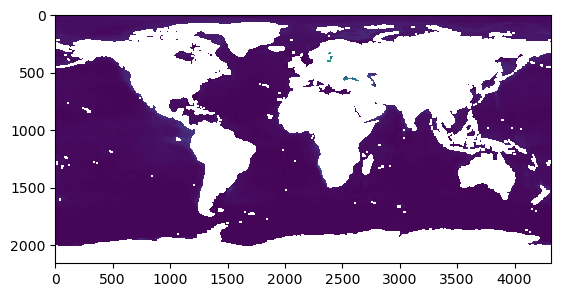

In [10]:
plt.imshow(np.mean(prediction_dist_overlapped, axis = 0))

In [34]:
import numpy as np

# Assuming prediction_dist_overlapped has size [100, 2160, 4320]
prediction_dist_overlapped_shape = prediction_dist_overlapped.shape

# Calculate the number of chunks
num_chunks = 360

# Calculate the size of each chunk along the second dimension
chunk_size = prediction_dist_overlapped_shape[1] // num_chunks

# Reshape the array into chunks
chunks = np.reshape(prediction_dist_overlapped, (prediction_dist_overlapped_shape[0], num_chunks, chunk_size, prediction_dist_overlapped_shape[2]))

# Now, 'chunks' is an array of size [100, 360, 6, 4320]


In [35]:
chunks[:, 0, :, :].shape

(100, 6, 4320)

In [8]:
# -*- coding: utf-8 -*-
"""
@author: wasy
"""
#STEP 1: IMPORT LIBRARIES ----------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd

from scipy import stats
from scipy.optimize import curve_fit
from scipy import asarray as ar,exp

#close all opened figure
plt.close("all")


# Initialize lists to store optimized parameters and covariance matrices for each point
param_opt_all = np.empty([3, prediction_dist_overlapped.shape[1], prediction_dist_overlapped.shape[2]])
cov_matrix_all = np.empty([3, 3, prediction_dist_overlapped.shape[1], prediction_dist_overlapped.shape[2]])
tolerance_all = np.empty([ prediction_dist_overlapped.shape[1], prediction_dist_overlapped.shape[2]])
failed_fits = []
failed_fits_num = 0


# Given covariance matrix shape
covariance_matrix_shape = (3, 3)

# Create a NaN matrix of the same shape
nan_matrix = np.full(covariance_matrix_shape, np.nan)

import concurrent.futures

def fit_gaussian_parallel(i, j):
    x_data = prediction_dist_overlapped[:, i, j]

    if np.isnan(x_data).any():
        param_opt_all[:, i, j] = np.array([np.nan, np.nan, np.nan])
        cov_matrix_all[:, :, i, j] = nan_matrix
        # failed_fits.append((i, j, str(e)))
        return

    hist, bin_edges = np.histogram(x_data, bins=100)
    hist = hist / sum(hist)

    n = len(hist)
    x_hist = np.zeros((n), dtype=float)
    for ii in range(n):
        x_hist[ii] = (bin_edges[ii + 1] + bin_edges[ii]) / 2

    y_hist = hist
    mean = sum(x_hist * y_hist) / sum(y_hist)
    sigma = sum(y_hist * (x_hist - mean) ** 2) / sum(y_hist)

    tolerance = 1e-10  # Initial tolerance value
    max_iterations = 10  # Maximum number of iterations
    iteration = 0

    while iteration < max_iterations:
        try:
            # Gaussian least-square fitting process
            param_optimised, param_covariance_matrix = curve_fit(
                gaus, x_hist, y_hist, p0=[max(y_hist), mean, sigma], maxfev=5000, ftol=tolerance
            )

            # If the fit is successful, break out of the loop
            break

        except Exception as e:
            # If the fit fails, increase the tolerance for the next iteration
            tolerance *= 10
            iteration += 1

    if iteration == max_iterations:
        # If no successful fit is found, handle it as needed
        param_opt_all[:, i, j] = np.array([np.nan, np.nan, np.nan])
        cov_matrix_all[:, :, i, j] = nan_matrix
        failed_fits.append((i, j, "Fit failed even after increasing tolerance"))
    else:
        # Append the successful results to the lists
        param_opt_all[:, i, j] = param_optimised
        cov_matrix_all[:, :, i, j] = param_covariance_matrix
        tolerance_all[i, j] = tolerance

# Iterate over each point in the matrix using ThreadPoolExecutor
with concurrent.futures.ThreadPoolExecutor() as executor:
    futures = []
    for i in range(min(21, prediction_dist_overlapped.shape[1])):
        for j in range(min(21, prediction_dist_overlapped.shape[2])):
            futures.append(executor.submit(fit_gaussian_parallel, i, j))

    # Wait for all tasks to complete
    concurrent.futures.wait(futures)
     # Use as_completed to iterate over completed futures
    for future in concurrent.futures.as_completed(futures):
        # Get the result or exception from the future
        try:
            future.result()
        except Exception as e:
            print(f"Exception: {e}")
        
        # Track progress
        completed_count = len([f for f in futures if f.done()])
        total_count = len(futures)
        progress_percentage = (completed_count / total_count) * 100
        print(f"Progress: {completed_count}/{total_count} ({progress_percentage:.2f}%)")


"""
for i in range(prediction_dist_overlapped.shape[1]):
    if i>0:
        break
    for j in range(prediction_dist_overlapped.shape[2]):
        if j>5:
            break
        x_data = prediction_dist_overlapped[:, i, j]

        if np.isnan(x_data).any():
            param_opt_all[:, i, j] = np.array([np.nan, np.nan, np.nan])
            cov_matrix_all[:, :, i, j] = nan_matrix
            continue

        # Calculate mean and standard deviation directly from data
        mean = np.mean(x_data)
        sigma = np.std(x_data)

        try:
            # Gaussian least-square fitting process
            param_optimised, param_covariance_matrix = curve_fit(
                gaus, x_data, np.ones_like(x_data), p0=[max(x_data), mean, sigma], maxfev=5000
            )

            # Append the results to the lists
            param_opt_all[:, i, j] = param_optimised
            cov_matrix_all[:, :, i, j] = param_covariance_matrix

        except Exception as e:
            print(f"Failed fit at ({i}, {j}) - Number: {failed_fits_num}")
            # Handle the case where fitting fails
            param_opt_all[:, i, j] = np.array([np.nan, np.nan, np.nan])
            cov_matrix_all[:, :, i, j] = nan_matrix
            failed_fits.append((i, j, str(e)))
"""
"""
from multiprocessing import Pool

def process_point(args):
    i, j, x_data = args
    try:
        hist, bin_edges = np.histogram(x_data)
        hist = hist / sum(hist)

        n = len(hist)
        x_hist = np.zeros((n), dtype=float)
        for ii in range(n):
            x_hist[ii] = (bin_edges[ii + 1] + bin_edges[ii]) / 2

        y_hist = hist
        mean = sum(x_hist * y_hist) / sum(y_hist)
        sigma = sum(y_hist * (x_hist - mean)) / sum(y_hist)

        # Gaussian least-square fitting process
        param_optimised, param_covariance_matrix = curve_fit(
            gaus, x_hist, y_hist, p0=[max(y_hist), mean, sigma], maxfev=5000
        )

        return param_optimised, param_covariance_matrix
    except Exception as e:
        print("heyy!!")
        return np.array([np.nan, np.nan, np.nan]), np.full(covariance_matrix_shape, np.nan)
        #failed_fits.append((i, j))
# Prepare a list of arguments for each point
point_args = [(i, j, prediction_dist_overlapped[:, i, j])
              for i in range(prediction_dist_overlapped.shape[1])
              for j in range(prediction_dist_overlapped.shape[2])]

# Create a Pool with the number of processes you want
with Pool() as pool:
    # Use map to apply the process_point function to each set of arguments in parallel
    results = pool.map(process_point, point_args)

# Extract the results
param_opt_list, cov_matrix_list = zip(*results)
        


"""

# Print fit Gaussian parameters
print("Fit parameters: ")
print("=====================================================")
print("C = ", param_optimised[0], "+-", np.sqrt(param_covariance_matrix[0, 0]))
print("X_mean =", param_optimised[1], "+-", np.sqrt(param_covariance_matrix[1, 1]))
print("sigma = ", param_optimised[2], "+-", np.sqrt(param_covariance_matrix[2, 2]))
print("actual mean = ", np.mean(x_data))
print("\n")

# Plotting the Gaussian curve
fig, ax = plt.subplots()
x_data_sorted = np.sort(x_data)
ax.plot(x_data_sorted, gaus(x_data_sorted, *param_optimised), 'r.:', label='Gaussian fit')

# Normalize the histogram values
weights = np.ones_like(x_data) / len(x_data)
ax.hist(x_data, weights=weights, alpha=0.5, label='Data',bins = 100)

# Setting the label, title, and grid of the plot
ax.set_xlabel("Data: Random variable")
ax.set_ylabel("Probability")
ax.grid(True)
ax.legend()

plt.show()



Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (100.00%)
Progress: 441/441 (1

NameError: name 'param_optimised' is not defined

In [6]:
param_opt_all.shape


(3, 2160, 4320)

In [29]:
x_data = np.random.standard_normal(size=(100))

In [30]:
from scipy.stats import norm
from scipy.optimize import curve_fit
def gaussian_func(x, mu, sigma):
    return norm.pdf(x, mu, sigma)

def gaus(X, C, X_mean, sigma):
    return C * np.exp(-(X - X_mean)**2 / (2 * sigma**2))
hist, bin_edges = np.histogram(x_data, bins=100)
hist = hist / sum(hist)

n = len(hist)
x_hist = np.zeros((n), dtype=float)
for ii in range(n):
    x_hist[ii] = (bin_edges[ii + 1] + bin_edges[ii]) / 2

y_hist = hist
mean = sum(x_hist * y_hist) / sum(y_hist)
sigma = sum(y_hist * (x_hist - mean)**2) / sum(y_hist)

param_optimised, param_covariance_matrix = curve_fit(
                    gaus, x_hist, y_hist, p0=[max(y_hist), mean, sigma], maxfev=5000
                )

Fit parameters: 
C =  0.01884802360281783 +- 0.0017929423883033245
X_mean = -0.04602365646308074 +- 0.10041358953949625
sigma =  0.9161051494172472 +- 0.10342795748940589
actual mean =  -0.11060399625596837




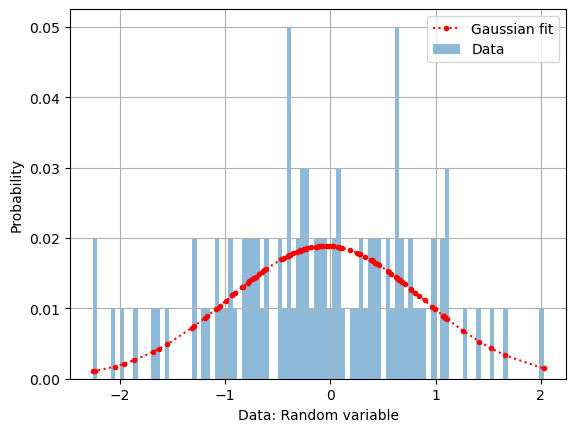

Probability at X=0: 0.001556413122984021


In [37]:
# Print fit Gaussian parameters
print("Fit parameters: ")
print("=====================================================")
print("C = ", param_optimised[0], "+-", np.sqrt(param_covariance_matrix[0, 0]))
print("X_mean =", param_optimised[1], "+-", np.sqrt(param_covariance_matrix[1, 1]))
print("sigma = ", param_optimised[2], "+-", np.sqrt(param_covariance_matrix[2, 2]))
print("actual mean = ", np.mean(x_data))
print("\n")

# Plotting the Gaussian curve
fig, ax = plt.subplots()
x_data_sorted = np.sort(x_data)
ax.plot(x_data_sorted, gaus(x_data_sorted, *param_optimised), 'r.:', label='Gaussian fit')

# Normalize the histogram values
weights = np.ones_like(x_data) / len(x_data)
ax.hist(x_data, weights=weights, alpha=0.5, label='Data',bins = 100)

# Setting the label, title, and grid of the plot
ax.set_xlabel("Data: Random variable")
ax.set_ylabel("Probability")
ax.grid(True)
ax.legend()

plt.show()
# After curve fitting
C, X_mean, sigma = param_optimised

# Evaluate the Gaussian function at X = 0
probability_at_0 = gaus(2, C, X_mean, sigma)
print(f"Probability at X=0: {probability_at_0}")


In [32]:
data_point = x_data

x_values = np.arange(len(data_point))
mu_init = np.mean(data_point)
sigma_init = np.std(data_point)
params, _ = curve_fit(gaussian_func, x_values, data_point, p0=[mu_init, sigma_init])

In [33]:
param_optimised

array([ 0.01884802, -0.04602366,  0.91610515])

In [34]:
params

array([-6.07556078,  0.51123393])

In [28]:
np.mean(x_data)

-0.23643736375929922

In [ ]:
param_opt_chunk


Fit parameters: 
C =  1.0000000001033114 +- inf
X_mean = 0.7084527096344713 +- inf
sigma =  10957.117067538918 +- inf
actual mean =  0.58705096463254




/tmp/ipykernel_2895854/2505155453.py:36: DeprecationWarning: scipy.exp is deprecated and will be removed in SciPy 2.0.0, use numpy.exp instead
  return C*exp(-(X-X_mean)**2/(2*sigma**2))


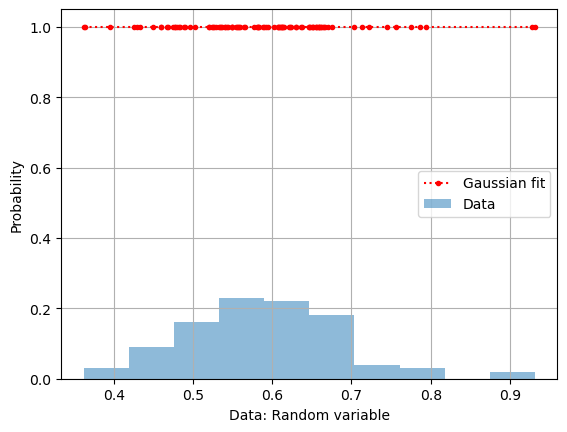

In [5]:
# Print fit Gaussian parameters
print("Fit parameters: ")
print("=====================================================")
print("C = ", param_optimised[0], "+-", np.sqrt(param_covariance_matrix[0, 0]))
print("X_mean =", param_optimised[1], "+-", np.sqrt(param_covariance_matrix[1, 1]))
print("sigma = ", param_optimised[2], "+-", np.sqrt(param_covariance_matrix[2, 2]))
print("actual mean = ", np.mean(x_data))
print("\n")

# Plotting the Gaussian curve
fig, ax = plt.subplots()
x_data_sorted = np.sort(x_data)
ax.plot(x_data_sorted, gaus(x_data_sorted, *param_optimised), 'r.:', label='Gaussian fit')

# Normalize the histogram values
weights = np.ones_like(x_data) / len(x_data)
ax.hist(x_data, weights=weights, alpha=0.5, label='Data')

# Setting the label, title, and grid of the plot
ax.set_xlabel("Data: Random variable")
ax.set_ylabel("Probability")
ax.grid(True)
ax.legend()

plt.show()

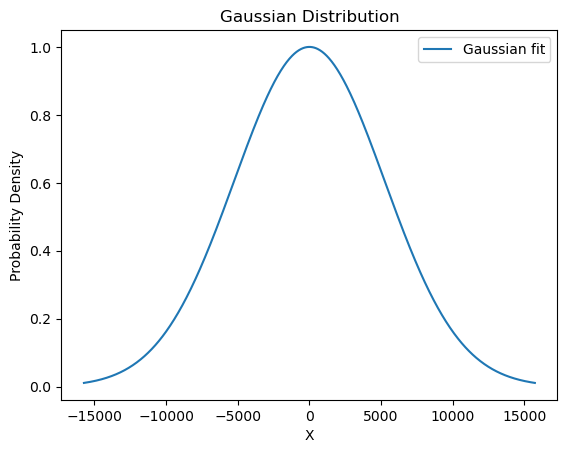

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import exp

# Define the Gaussian function
def gaus(X, C, X_mean, sigma):
    return C * np.exp(-(X - X_mean)**2 / (2 * sigma**2))

# Parameters
C =  1.0000000001215277
X_mean = 0.6301407645175615
sigma =  5244.40391107064 

# Generate x values
x_values = np.linspace(X_mean - 3 * sigma, X_mean + 3 * sigma, 1000)

# Calculate y values using the Gaussian function
y_values = gaus(x_values, C, X_mean, sigma)

# Plot the Gaussian curve
plt.plot(x_values, y_values, label='Gaussian fit')
plt.title('Gaussian Distribution')
plt.xlabel('X')
plt.ylabel('Probability Density')
plt.legend()
plt.show()

In [5]:
i

25

In [ ]:
import multiprocessing
import itertools
# Close all opened figures
plt.close("all")

# Initialize lists to store optimized parameters and covariance matrices for each point
param_opt_all = np.zeros([3, prediction_dist_overlapped.shape[1], prediction_dist_overlapped.shape[2]])
cov_matrix_all = np.zeros([3, 3, prediction_dist_overlapped.shape[1], prediction_dist_overlapped.shape[2]])
failed_fits = []

# Given covariance matrix shape
covariance_matrix_shape = (3, 3)

# Create a NaN matrix of the same shape
nan_matrix = np.full(covariance_matrix_shape, np.nan)

# Calculating the Gaussian PDF values given Gaussian parameters and random variable X
def gaus(X, C, X_mean, sigma):
    return C * exp(-(X - X_mean) ** 2 / (2 * sigma ** 2))

# Function to fit a chunk of points
def fit_chunk(chunk):
    for indices in chunk:
        i, j = indices
        x_data = prediction_dist_overlapped[:, i, j]

        if np.isnan(x_data).any():
            param_opt_all[:, i, j] = np.array([np.nan, np.nan, np.nan])
            cov_matrix_all[:, :, i, j] = nan_matrix
            continue

        hist, bin_edges = np.histogram(x_data)
        hist = hist / sum(hist)

        n = len(hist)
        x_hist = np.zeros((n), dtype=float)
        for ii in range(n):
            x_hist[ii] = (bin_edges[ii + 1] + bin_edges[ii]) / 2

        y_hist = hist
        mean = sum(x_hist * y_hist) / sum(y_hist)
        sigma = sum(y_hist * (x_hist - mean) ** 2) / sum(y_hist)
        try:
            # Gaussian least-square fitting process
            param_optimised, param_covariance_matrix = curve_fit(
                gaus, x_hist, y_hist, p0=[max(y_hist), mean, sigma], maxfev=5000
            )

            # Append the results to the lists
            param_opt_all[:, i, j] = param_optimised
            cov_matrix_all[:, :, i, j] = param_covariance_matrix

        except Exception as e:
            print(f"Failed fit at ({i}, {j})")
            # Handle the case where fitting fails
            param_opt_all[:, i, j] = np.array([np.nan, np.nan, np.nan])
            cov_matrix_all[:, :, i, j] = nan_matrix
            failed_fits.append((i, j, str(e)))

# Generate all pairs of indices
index_pairs = list(itertools.product(range(prediction_dist_overlapped.shape[1]), range(prediction_dist_overlapped.shape[2])))

# Split the index pairs into chunks
num_processes = 64  # Adjust as needed
chunk_size = len(index_pairs) // num_processes
chunks = [index_pairs[i:i + chunk_size] for i in range(0, len(index_pairs), chunk_size)]

# Create a multiprocessing pool
with multiprocessing.Pool(processes=num_processes) as pool:
    # Map the function over all chunks
    pool.map(fit_chunk, chunks)

# Continue with the rest of your code after the parallel fitting process

/tmp/ipykernel_2065244/284285142.py:18: DeprecationWarning: scipy.exp is deprecated and will be removed in SciPy 2.0.0, use numpy.exp instead
  return C * exp(-(X - X_mean) ** 2 / (2 * sigma ** 2))
/tmp/ipykernel_2065244/284285142.py:18: DeprecationWarning: scipy.exp is deprecated and will be removed in SciPy 2.0.0, use numpy.exp instead
  return C * exp(-(X - X_mean) ** 2 / (2 * sigma ** 2))
/tmp/ipykernel_2065244/284285142.py:18: DeprecationWarning: scipy.exp is deprecated and will be removed in SciPy 2.0.0, use numpy.exp instead
  return C * exp(-(X - X_mean) ** 2 / (2 * sigma ** 2))
/tmp/ipykernel_2065244/284285142.py:18: DeprecationWarning: scipy.exp is deprecated and will be removed in SciPy 2.0.0, use numpy.exp instead
  return C * exp(-(X - X_mean) ** 2 / (2 * sigma ** 2))
/tmp/ipykernel_2065244/284285142.py:18: DeprecationWarning: scipy.exp is deprecated and will be removed in SciPy 2.0.0, use numpy.exp instead
  return C * exp(-(X - X_mean) ** 2 / (2 * sigma ** 2))
/tmp/ipyke

Failed fit at (405, 132)
Failed fit at (337, 2173)


/tmp/ipykernel_2065244/284285142.py:18: DeprecationWarning: scipy.exp is deprecated and will be removed in SciPy 2.0.0, use numpy.exp instead
  return C * exp(-(X - X_mean) ** 2 / (2 * sigma ** 2))
/tmp/ipykernel_2065244/284285142.py:18: DeprecationWarning: scipy.exp is deprecated and will be removed in SciPy 2.0.0, use numpy.exp instead
  return C * exp(-(X - X_mean) ** 2 / (2 * sigma ** 2))


Failed fit at (472, 3890)


/tmp/ipykernel_2065244/284285142.py:18: DeprecationWarning: scipy.exp is deprecated and will be removed in SciPy 2.0.0, use numpy.exp instead
  return C * exp(-(X - X_mean) ** 2 / (2 * sigma ** 2))


Failed fit at (438, 3881)
Failed fit at (405, 133)
Failed fit at (304, 98)


... (71 outputs left out)

/tmp/ipykernel_2065244/284285142.py:18: DeprecationWarning: scipy.exp is deprecated and will be removed in SciPy 2.0.0, use numpy.exp instead
  return C * exp(-(X - X_mean) ** 2 / (2 * sigma ** 2))



Failed fit at (1316, 1707)
Failed fit at (1113, 3466)

Failed fit at (1923, 4120)
Failed fit at (1957, 4195)
Failed fit at (1046, 1565)Failed fit at (338, 1043)


Failed fit at (405, 1109)
Failed fit at (810, 252)Failed fit at (1991, 1492)

Failed fit at (304, 1266)Failed fit at (1316, 1708)

Failed fit at (506, 2076)
Failed fit at (1586, 1411)Failed fit at (540, 1118)

Failed fit at (607, 2797)Failed fit at (1957, 4196)Failed fit at (1046, 1566)Failed fit at (1248, 3658)Failed fit at (1113, 3467)Failed fit at (1282, 2688)




Failed fit at (405, 1110)Failed fit at (1012, 3072)

Failed fit at (304, 1267)
Failed fit at (1991, 1493)
Failed fit at (810, 253)
Failed fit at (978, 3948)Failed fit at (540, 1366)


Failed fit at (1586, 1418)Failed fit at (1957, 4197)Failed fit at (1046, 1567)


Failed fit at (1113, 3468)
Failed fit at (473, 446)
Failed fit at (304, 1269)Failed fit at (810, 254)
Failed fit at (1721, 1250)Failed fit at (1248, 3661)

Failed fit at (506, 2080)Failed fit at (1991,

/tmp/ipykernel_2065244/284285142.py:18: RuntimeWarning: overflow encountered in scalar power
  return C * exp(-(X - X_mean) ** 2 / (2 * sigma ** 2))



Failed fit at (931, 2846)

Failed fit at (1901, 2551)Failed fit at (595, 1277)

Failed fit at (1998, 4193)Failed fit at (1729, 3042)

Failed fit at (1864, 3311)Failed fit at (457, 2208)Failed fit at (860, 1218)


Failed fit at (761, 1154)
Failed fit at (555, 2765)
Failed fit at (622, 2791)
Failed fit at (530, 2785)
Failed fit at (356, 2135)Failed fit at (53, 1862)Failed fit at (293, 1213)

Failed fit at (1933, 1228)
Failed fit at (1901, 2553)Failed fit at (1832, 1433)


Failed fit at (250, 2728)
Failed fit at (1964, 1437)Failed fit at (1092, 3453)Failed fit at (331, 1266)

Failed fit at (595, 1279)
Failed fit at (1998, 4194)Failed fit at (385, 2133)
Failed fit at (1729, 3045)


Failed fit at (457, 2210)Failed fit at (1864, 3313)

Failed fit at (761, 1156)Failed fit at (622, 2792)

Failed fit at (860, 1264)
Failed fit at (293, 1215)Failed fit at (1933, 1229)
Failed fit at (356, 2136)Failed fit at (1901, 2556)
Failed fit at (1832, 1441)

Failed fit at (331, 1267)Failed fit at (1092, 345

In [14]:

np.save("param_opt_all", param_opt_all)
np.save("cov_matrix_all", cov_matrix_all)


In [41]:
param_opt_all.shape

(3, 2160, 4320)

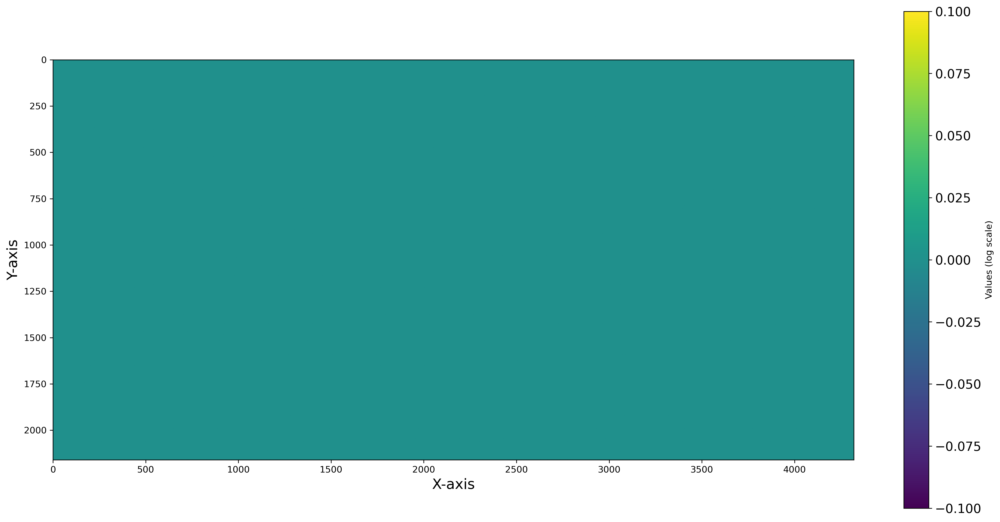

In [17]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np

# Assuming fit_params is a 3D array
#fit_params = np.random.rand(10, 10, 2)  # Replace this with your actual data

# Plotting
plt.figure(figsize=(20, 10), dpi = 300)
plt.imshow(param_opt_all[2,:,:], cmap='viridis')

# Adding colorbarparam_opt_all
cbar = plt.colorbar(label='Values (log scale)')
cbar.ax.tick_params(labelsize=14)

# Adding labels and title
plt.xlabel('X-axis', fontsize=16)
plt.ylabel('Y-axis', fontsize=16)

# Show the plot
plt.show()

In [18]:
param_opt_all

array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]])

In [20]:
param_covariance_matrix

array([[ 2.82491331e-04,  1.01779381e-05, -1.40430205e-04],
       [ 1.01779381e-05,  1.64092971e-04, -1.84864821e-05],
       [-1.40430205e-04, -1.84864821e-05,  1.93772911e-04]])

In [67]:
array_params = np.array(param_opt_list)

In [73]:
pred_plot = array_params[:, 1].reshape([2160, 4320])

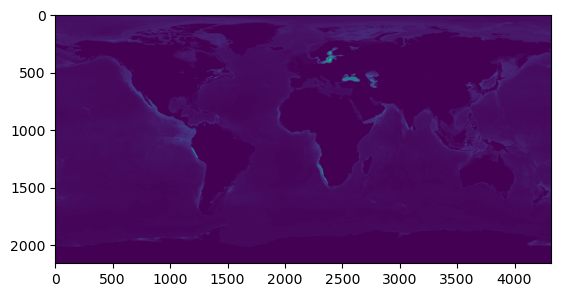

In [74]:
plt.imshow(pred_plot)

In [78]:
nan_count = np.sum(np.isnan(pred_plot))

In [79]:
nan_count

0

In [59]:
param_covariance_matrix

array([[ 6.24618640e-04,  7.69801859e-06, -1.11193605e-04],
       [ 7.69801859e-06,  4.87248771e-05, -4.86608084e-06],
       [-1.11193605e-04, -4.86608084e-06,  5.56605389e-05]])

In [57]:
j

2573

In [53]:
param_optimised

array([0.16281686, 0.87228466, 0.15794354])

In [43]:
param_optimised



array([0.18187037, 0.49663386, 0.12396819])

In [44]:
np.mean(x_data)

0.5015274787872661

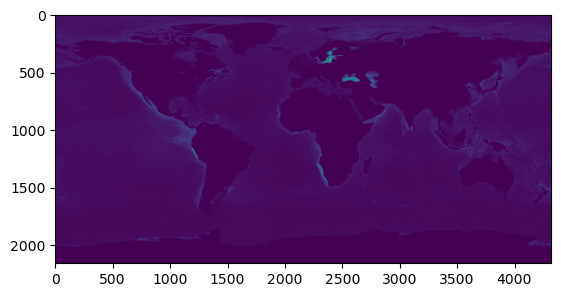

In [30]:
plt.imshow(pm_overlapped)

In [34]:
from scipy.stats import norm
from scipy.optimize import curve_fit
import numpy as np
from multiprocessing import Pool, Manager

# Define the Gaussian density function
def gaussian_density(x, mu, sigma):
    return 1 / (sigma * np.sqrt(2 * np.pi)) * np.exp(-(x - mu)**2 / (2 * sigma**2))


def fit_gaussian_point(point, failed_fits_count, failed_fit_details):
    i, j, data_point = point

    # Check if data_point contains NaN values, and skip fitting if it does
    if np.isnan(data_point).any():
        #print("nan!")
        return None
    
    x_values = np.arange(len(data_point))
    #print(x_values)
    try:
        # Fit a Gaussian distribution to the data with an improved initial guess
        #print(data_point)
        mu_init = np.mean(data_point)
        sigma_init = np.std(data_point)
        params, covariance = curve_fit(gaussian_density, data_point, np.ones_like(data_point), p0=[mu_init, sigma_init])
        #print(mu_init)
        #print(params)
        return i, j, params
    except Exception as e:
        #print(f"Fit failed for point ({i}, {j}): {str(e)}")
        failed_fits_count.value += 1
        failed_fit_details.append((i, j, str(e)))
        # Write details of failed fits to a file
        with open("failed_fits.txt", "a") as file:
            file.write(f"Failed fit at point ({i}, {j})\n")
        return None

def fit_gaussian_to_predictions(predictions_sum):
    # Assume predictions_sum is your array of shape (100, 6, 4320)
    num_samples, num_points_x, num_points_y = predictions_sum.shape

    # Fitting parameters for each point
    fit_params_gaussian = np.zeros((num_points_x, num_points_y, 2))  # Assuming Gaussian has two parameters (mu, sigma)

    # Count the number of points where the fitting process fails
    manager = Manager()
    failed_fits_count = manager.Value('i', 0)

    # List to store details of failed fits
    failed_fit_details = []

    # Create a list of tuples for each point and its data
    data_points = [(i, j, predictions_sum[:, i, j]) for i in range(num_points_x) for j in range(num_points_y)]

    # Use multiprocessing Pool to parallelize the fitting process
    with Pool() as pool:
        results = pool.starmap(fit_gaussian_point, [(point, failed_fits_count, failed_fit_details) for point in data_points])

    # Process the results
    for result in results:
        if result is not None:
            i, j, params = result
            fit_params_gaussian[i, j] = params # if it is a failed it, the parameters are zeros

    return fit_params_gaussian, failed_fits_count.value, failed_fit_details

In [35]:
failed_fits_all = []
i = 0
fit_params, failed_fits, failed_fit_details = fit_gaussian_to_predictions(prediction_dist_overlapped)
failed_fits_all.append(failed_fits)
print(i)

0


In [9]:
fit_params.shape

(2160, 4320, 2)

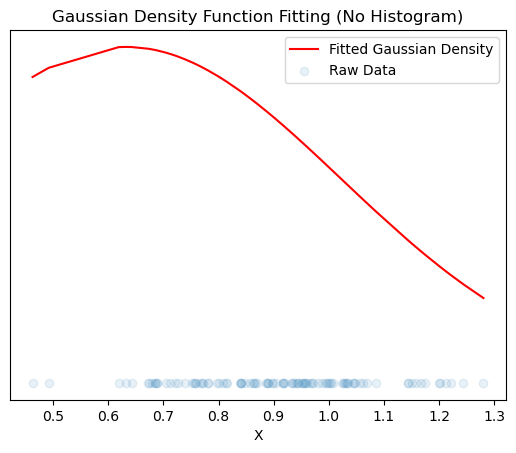

In [41]:
data_sorted = np.sort(np.array([0.8992284,0.64216938,0.72083345,0.61897456,0.95636716,1.03103221
,0.86562204,0.91620787,0.89651731,1.22087333,1.15084729,1.05662739
,1.00728028,0.88969563,0.67865741,0.7553292,0.88895589,0.88783405
,0.94396591,0.92119506,0.95072876,1.04710319,0.68896078,0.86210692
,0.80161336,0.99769682,1.06250473,0.9811982,1.20125157,1.16668452
,1.04486901,0.76980455,1.14434303,0.98800745,0.95748919,0.46262657
,0.91700443,0.83856155,0.88638888,0.67279094,0.68450257,1.24396308
,0.86992251,0.67467948,0.71273175,0.68551212,0.68835024,0.94410795
,0.75988937,0.75196944,0.91762554,1.03477068,0.83984773,0.93297423
,0.97185578,0.95581373,1.06872661,0.63153915,0.84088853,0.78082185
,0.72608487,0.96681017,0.9691959,0.90442117,0.93694084,1.15730095
,0.77216115,1.03387009,0.93346171,0.96019669,0.49184222,0.78163356
,0.95062926,0.81595537,1.20023368,1.08629296,1.00286424,0.76632207
,0.86427943,0.75754356,1.02414923,0.94081433,1.28054607,0.81361242
,0.99281039,0.80737341,0.84139903,0.73863604,1.14321148,1.02785847
,1.17532813,0.8481121,1.02728824,0.79722016,1.00377424,1.21307479
,0.99616684,0.85772861,0.70401102,1.04449312]))
# Plot the raw data and the fitted Gaussian density function
plt.plot(data_sorted, gaussian_density(data_sorted, fit_params[0][0][0], fit_params[0][0][1]), color='red', label='Fitted Gaussian Density')
plt.scatter(data_sorted, np.zeros_like(data_sorted), alpha=0.1, label='Raw Data')
plt.title('Gaussian Density Function Fitting (No Histogram)')
plt.xlabel('X')
plt.yticks([])  # Hide y-axis ticks for better visualization
plt.legend()
plt.show()

# Print the optimized 

In [42]:
from scipy.stats import shapiro

# Example: data_sorted is your sorted dataset, and fit_params contains the parameters of your fitted Gaussian distribution
#data_sorted = np.sort(data)
mu, sigma = fit_params[0][0]

# Compute the Gaussian density for the sorted data
gaussian_density_values = gaussian_density(data_sorted, mu, sigma)

# Shapiro-Wilk test
stat, p_value = shapiro(gaussian_density_values)
print(f'Statistic: {stat}, p-value: {p_value}')

# Check if p-value is greater than your significance level (e.g., 0.05)
if p_value > 0.05:
    print('The distribution appears to be Gaussian.')
else:
    print('The distribution does not appear to be Gaussian.')

Statistic: 0.9348333477973938, p-value: 9.460484579904005e-05
The distribution does not appear to be Gaussian.


In [43]:
gaussian_density(data_sorted, mu, sigma)

array([0.92902063, 0.95690725, 1.019826  , 1.02038933, 1.02004317,
       1.01484471, 1.01432125, 1.01314219, 1.01122224, 1.01086812,
       1.00983718, 1.00960859, 1.00321622, 0.99885322, 0.99437353,
       0.99125319, 0.98311623, 0.97344573, 0.97084587, 0.96909702,
       0.96721394, 0.96189121, 0.95891356, 0.95686074, 0.94905788,
       0.94830598, 0.93320248, 0.92872238, 0.92270443, 0.91600573,
       0.91344265, 0.88743928, 0.88589323, 0.88463709, 0.88401934,
       0.87579692, 0.86370758, 0.85808683, 0.85527161, 0.85352324,
       0.84787982, 0.82569008, 0.8237008 , 0.82215214, 0.82112885,
       0.81161523, 0.8077967 , 0.80042536, 0.78342932, 0.78226817,
       0.78136171, 0.77613465, 0.75868373, 0.75795522, 0.75274213,
       0.74691072, 0.74214572, 0.74193054, 0.73201436, 0.73186252,
       0.72408186, 0.72323266, 0.72150961, 0.71734439, 0.70712842,
       0.70342955, 0.69929775, 0.6847256 , 0.6740538 , 0.66650497,
       0.66122061, 0.65880963, 0.65065784, 0.64922102, 0.64368

/tmp/ipykernel_1693803/1393154981.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(gaussian_density(data_sorted, mu, sigma))
/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating i

<Axes: ylabel='Density'>

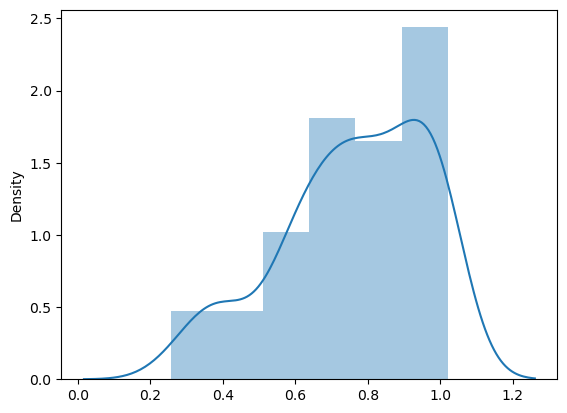

In [47]:
import seaborn as sns
sns.distplot(gaussian_density(data_sorted, mu, sigma))

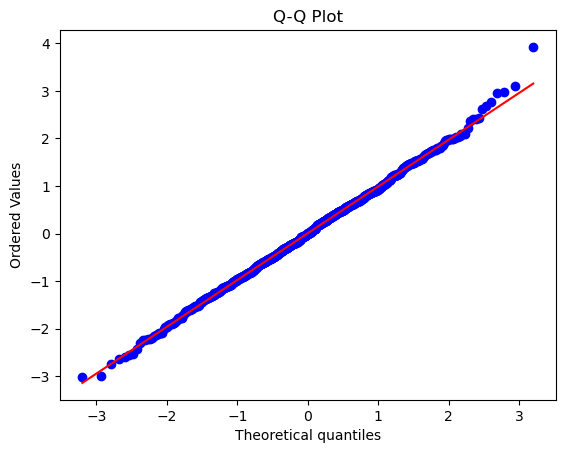

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import probplot

# Example: data is your dataset
data = np.random.normal(0, 1, 1000)

# Create a Q-Q plot
probplot(data, plot=plt)
plt.title('Q-Q Plot')
plt.show()


In [135]:
fit_params[0][0][0]

0.9073608867420614

In [136]:
np.mean(data_sorted)

0.9073608862

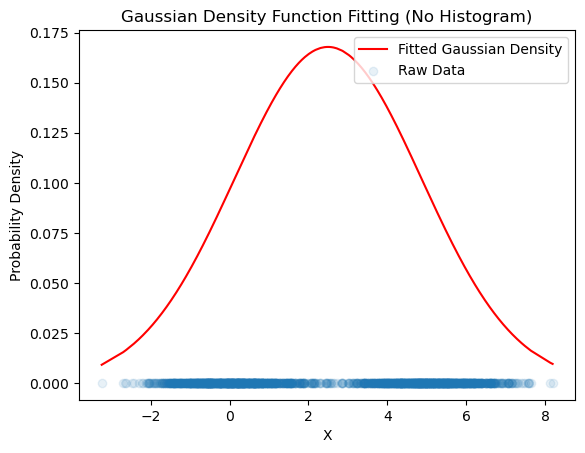

Optimized mean (mu): 2.4989480886524635
Optimized standard deviation (sigma): 2.3759555773424843


In [36]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Define the Gaussian density function
def gaussian_density(x, mu, sigma):
    return 1 / (sigma * np.sqrt(2 * np.pi)) * np.exp(-(x - mu)**2 / (2 * sigma**2))

# Generate synthetic data with noise
np.random.seed(42)  # for reproducibility
data = np.concatenate([np.random.normal(0, 1, 1000), np.random.normal(5, 1, 1000)])
# Sort the data for better visualization
data_sorted = np.sort(data)

# Calculate the probability density for each data point
pdf_values = np.zeros_like(data_sorted)
for i, x in enumerate(data_sorted):
    pdf_values[i] = np.sum(data_sorted < x) / len(data_sorted)

# Initial guesses for the parameters
mu_init = np.mean(data)
sigma_init = np.std(data)

# Fit the data to the Gaussian density function using curve_fit
params, covariance = curve_fit(gaussian_density,  data_sorted, np.ones_like(data_sorted), p0=[mu_init, sigma_init])

# Extract optimized parameters
mu_optimized, sigma_optimized = params

# Plot the raw data and the fitted Gaussian density function
plt.plot(data_sorted, gaussian_density(data_sorted, mu_optimized, sigma_optimized), color='red', label='Fitted Gaussian Density')
plt.scatter(data_sorted,np.zeros_like(data), alpha=0.1, label='Raw Data')
plt.title('Gaussian Density Function Fitting (No Histogram)')
plt.xlabel('X')
plt.ylabel('Probability Density')
plt.legend()
plt.show()

# Print the optimized mean and standard deviation
print(f"Optimized mean (mu): {mu_optimized}")
print(f"Optimized standard deviation (sigma): {sigma_optimized}")

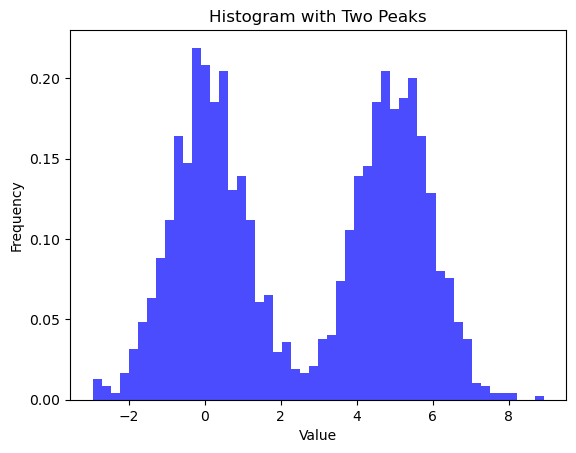

In [29]:
import numpy as np
import matplotlib.pyplot as plt

# Generate data with two peaks
data = np.concatenate([np.random.normal(0, 1, 1000), np.random.normal(5, 1, 1000)])

# Plot the histogram
plt.hist(data, bins=50, color='blue', alpha=0.7, density=True)
plt.title('Histogram with Two Peaks')
plt.xlabel('Value')
plt.ylabel('Frequency')

plt.show()

In [20]:
np.mean(data)

3.028998083733488

In [44]:
np.arange(10)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [37]:
fit_params

array([[[ 8.71597187e+03,  2.63632949e+03,  1.97035253e+03],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 1.92805786e+02,  6.48744770e+01,  1.04731194e+02],
        [ 2.44076302e+02,  7.27925166e+01,  1.34498688e+02],
        [ 3.65514996e+02,  4.13000297e+00,  2.00352616e+02]],

       [[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 2.38286059e+04,  8.09354516e+03,  9.57273912e+03],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00]],

       [[ 2.56573443e+02,  6.38264839e+01,  1.44269151e+02],
        [ 1.35222829e+02,  5.97330626e+01,  8.44360787e+01],
        [ 5.56751256e+02,  4.16129711e+01,  4.22016405e+02],
        [ 4.49558155e+02,  4.23324853e+01,  1.94134379e+02],
        [ 4.16681674e+02,  3.92401863e+01,  1.72657091e+02]],

       [[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 3.062931

In [13]:
failed_fits

0

In [9]:
failed_fits/(2160*4320)

0.004116833847736625

In [10]:
fit_params.shape

(2160, 4320, 2)

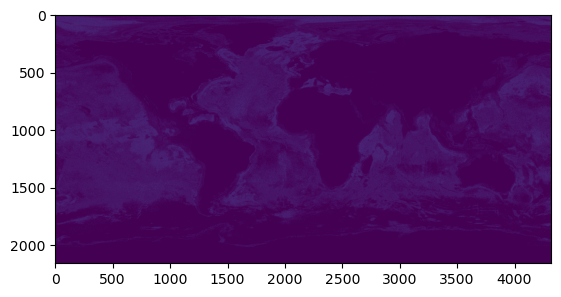

In [11]:
plt.imshow(fit_params[:,:,1])

In [5]:
np.save("fit_params", fit_params)

In [12]:
fit_params = np.load("fit_params.npy")

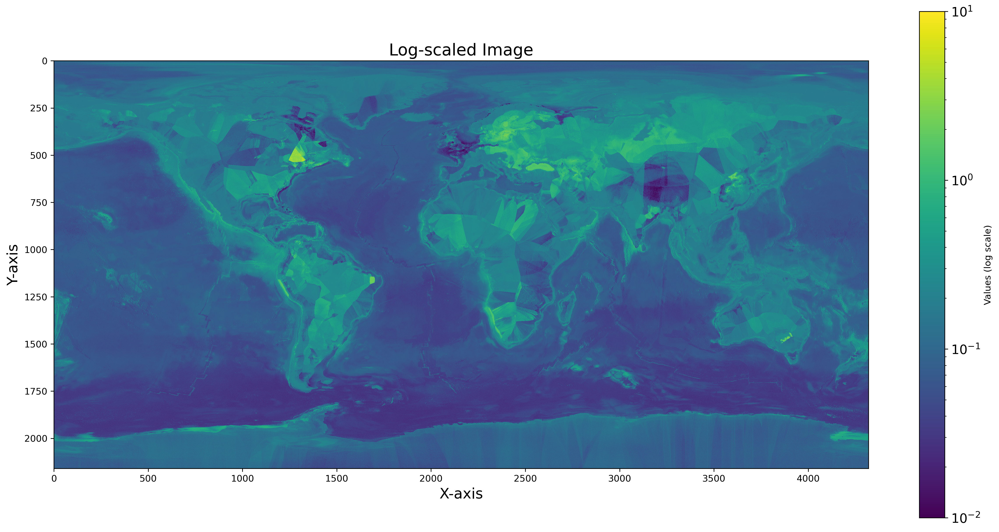

In [17]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np

# Assuming fit_params is a 3D array
#fit_params = np.random.rand(10, 10, 2)  # Replace this with your actual data

# Plotting
plt.figure(figsize=(20, 10), dpi = 300)
plt.imshow(np.std(prediction_dist_overlapped, axis = 0), norm=LogNorm(vmin = 1e-2, vmax = 1e1), cmap='viridis')

# Adding colorbar
cbar = plt.colorbar(label='Values (log scale)')
cbar.ax.tick_params(labelsize=14)

# Adding labels and title
plt.xlabel('X-axis', fontsize=16)
plt.ylabel('Y-axis', fontsize=16)
plt.title('Log-scaled Image', fontsize=18)

# Show the plot
plt.show()

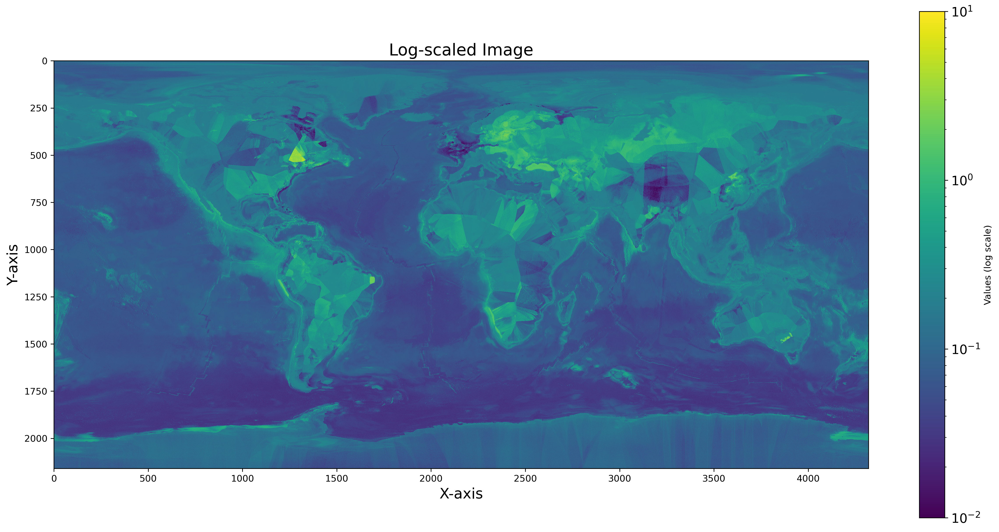

In [16]:
#plt.imshow(pm_overlapped)
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np

# Assuming fit_params is a 3D array
#fit_params = np.random.rand(10, 10, 2)  # Replace this with your actual data

# Plotting
plt.figure(figsize=(20, 10), dpi = 300)
plt.imshow(fit_params[:, :, 1], norm=LogNorm(vmin = 1e-2, vmax = 1e1), cmap='viridis')

# Adding colorbar
cbar = plt.colorbar(label='Values (log scale)')
cbar.ax.tick_params(labelsize=14)

# Adding labels and title
plt.xlabel('X-axis', fontsize=16)
plt.ylabel('Y-axis', fontsize=16)
plt.title('Log-scaled Image', fontsize=18)

# Show the plot
plt.show()